# Stock Market Dataset — Exploratory Data Analysis

**Project:** Stock Performance Prediction (RNN)

This notebook performs a deep exploratory analysis of the stock market dataset to build context for designing a recurrent neural network (RNN) model. We examine data structure, coverage, quality, distributional properties, and time-series characteristics that will inform feature engineering, target definition, and modeling strategy.

> **After a kernel restart:** use **Run → Run All Cells** (or run sequentially from Section 1). Later cells depend on imports and variables (`plt`, `aapl`, `aapl_ret`, etc.) created earlier.

---

## Dataset Overview

| Component | Description |
|-----------|-------------|
| `symbols_valid_meta.csv` | Metadata for ~8,049 traded symbols (exchange, ETF flag, financial status) |
| `stocks/` | ~5,884 individual equity CSV files |
| `etfs/` | ~2,165 ETF CSV files |
| **Columns per file** | `Date`, `Open`, `High`, `Low`, `Close`, `Adj Close`, `Volume` |
| **Date range** | Varies by symbol (~1962–2020); most data ends **2020-04-01** |

## 1. Setup & Configuration

**Kernel (recommended):** Select **Python (stock-performance-prediction)** or **`.venv (Python 3.9.x)`** from this project folder via the kernel picker (top-right).

In [1]:
import importlib.util
import subprocess
import sys
import warnings
from pathlib import Path

REQUIRED_PACKAGES = ["matplotlib", "numpy", "pandas", "seaborn", "scipy"]


def ensure_packages(packages: list[str]) -> None:
    missing = [pkg for pkg in packages if importlib.util.find_spec(pkg) is None]
    if not missing:
        return
    try:
        import pip  # noqa: F401
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "ensurepip", "--upgrade"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])


ensure_packages(REQUIRED_PACKAGES)
print(f"Python: {sys.executable}")

Python: /Users/franciskanu/Documents/Education/Programing for Data Analytics/.venv/bin/python


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.05)
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 100

def find_project_root() -> Path:
    """Locate project root by searching upward for the dataset folder."""
    candidates = [Path.cwd()]
    if Path.cwd().name == "notebooks":
        candidates.append(Path.cwd().parent)
    candidates.extend(Path.cwd().parents)

    for path in candidates:
        if (path / "Stock Market Dataset").exists():
            return path
    return Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()


PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "Stock Market Dataset"
STOCKS_DIR = DATA_DIR / "stocks"
ETFS_DIR = DATA_DIR / "etfs"
META_PATH = DATA_DIR / "symbols_valid_meta.csv"

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_DIR}\n"
        f"Current working directory: {Path.cwd()}\n"
        "Upload 'Stock Market Dataset' to the project root or run from the project directory."
    )

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset path: {DATA_DIR}")

Project root: /Users/franciskanu/University/Courses/Semester 2/BIT4.2C - Programming for Data Analytics (SS 26)/Final Project - Stock Performance Prediction
Dataset path: /Users/franciskanu/University/Courses/Semester 2/BIT4.2C - Programming for Data Analytics (SS 26)/Final Project - Stock Performance Prediction/Stock Market Dataset


## 2. Helper Functions

In [3]:
def load_price_data(symbol: str, asset_type: str = "stock") -> pd.DataFrame:
    """Load OHLCV data for a single symbol."""
    folder = STOCKS_DIR if asset_type == "stock" else ETFS_DIR
    path = folder / f"{symbol}.csv"
    if not path.exists():
        raise FileNotFoundError(f"No data file for {symbol} in {folder}")
    df = pd.read_csv(path, parse_dates=["Date"])
    df = df.sort_values("Date").reset_index(drop=True)
    df["Symbol"] = symbol
    return df


def add_returns(df: pd.DataFrame, price_col: str = "Adj Close") -> pd.DataFrame:
    """Add log and simple returns, plus intraday range."""
    out = df.copy()
    out["log_return"] = np.log(out[price_col] / out[price_col].shift(1))
    out["simple_return"] = out[price_col].pct_change()
    out["intraday_range"] = (out["High"] - out["Low"]) / out["Close"]
    out["overnight_gap"] = (out["Open"] - out["Close"].shift(1)) / out["Close"].shift(1)
    return out


def ensure_aapl_returns():
    """Load AAPL OHLCV and return series if not already in this kernel session."""
    global aapl, aapl_ret
    if "aapl" not in globals() or aapl is None:
        aapl = load_price_data("AAPL")
    if "aapl_ret" not in globals() or aapl_ret is None:
        aapl_ret = add_returns(aapl).dropna(subset=["log_return"])
    return aapl, aapl_ret


def scan_directory(directory: Path, sample_size=None, seed: int = 42) -> pd.DataFrame:
    """Scan CSV files and return coverage / quality summary per symbol."""
    files = sorted(directory.glob("*.csv"))
    if sample_size and sample_size < len(files):
        rng = np.random.default_rng(seed)
        files = list(rng.choice(files, size=sample_size, replace=False))

    records = []
    for path in files:
        try:
            df = pd.read_csv(path, parse_dates=["Date"])
            records.append({
                "symbol": path.stem,
                "rows": len(df),
                "start_date": df["Date"].min(),
                "end_date": df["Date"].max(),
                "null_count": int(df.isnull().sum().sum()),
                "zero_volume_days": int((df["Volume"] == 0).sum()),
                "duplicate_dates": int(df["Date"].duplicated().sum()),
            })
        except Exception as exc:
            records.append({"symbol": path.stem, "error": str(exc)})
    return pd.DataFrame(records)

## 3. Metadata Exploration

The metadata file describes each symbol's listing exchange, whether it is an ETF, and financial status flags. Understanding this landscape helps decide which universe of assets to include in the RNN training set.

In [4]:
meta = pd.read_csv(META_PATH)
print(f"Metadata shape: {meta.shape}")
meta.head()

Metadata shape: (8049, 12)


,Nasdaq Traded,Symbol,Security Name,Listing Exchange,Market Category,ETF,Round Lot Size,Test Issue,Financial Status,CQS Symbol,NASDAQ Symbol,NextShares
0,Y,A,"Agilent Technologies, Inc. Common Stock",N,,N,100.0,N,NaN,A,A,N
1,Y,AA,Alcoa Corporation Common Stock,N,,N,100.0,N,NaN,AA,AA,N
2,Y,AAAU,Perth Mint Physical Gold ETF,P,,Y,100.0,N,NaN,AAAU,AAAU,N
3,Y,AACG,ATA Creativity Global - American Depositary Sh...,Q,G,N,100.0,N,N,NaN,AACG,N
4,Y,AADR,AdvisorShares Dorsey Wright ADR ETF,P,,Y,100.0,N,NaN,AADR,AADR,N


In [5]:
print("Column dtypes and missing values:\n")
meta.info()

print("\nDuplicate symbols:", meta["Symbol"].duplicated().sum())

Column dtypes and missing values:

<class 'pandas.DataFrame'>
RangeIndex: 8049 entries, 0 to 8048
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Nasdaq Traded     8049 non-null   str    
 1   Symbol            8049 non-null   str    
 2   Security Name     8049 non-null   str    
 3   Listing Exchange  8049 non-null   str    
 4   Market Category   8049 non-null   str    
 5   ETF               8049 non-null   str    
 6   Round Lot Size    8049 non-null   float64
 7   Test Issue        8049 non-null   str    
 8   Financial Status  3383 non-null   str    
 9   CQS Symbol        4666 non-null   str    
 10  NASDAQ Symbol     8049 non-null   str    
 11  NextShares        8049 non-null   str    
dtypes: float64(1), str(11)
memory usage: 754.7 KB

Duplicate symbols: 0


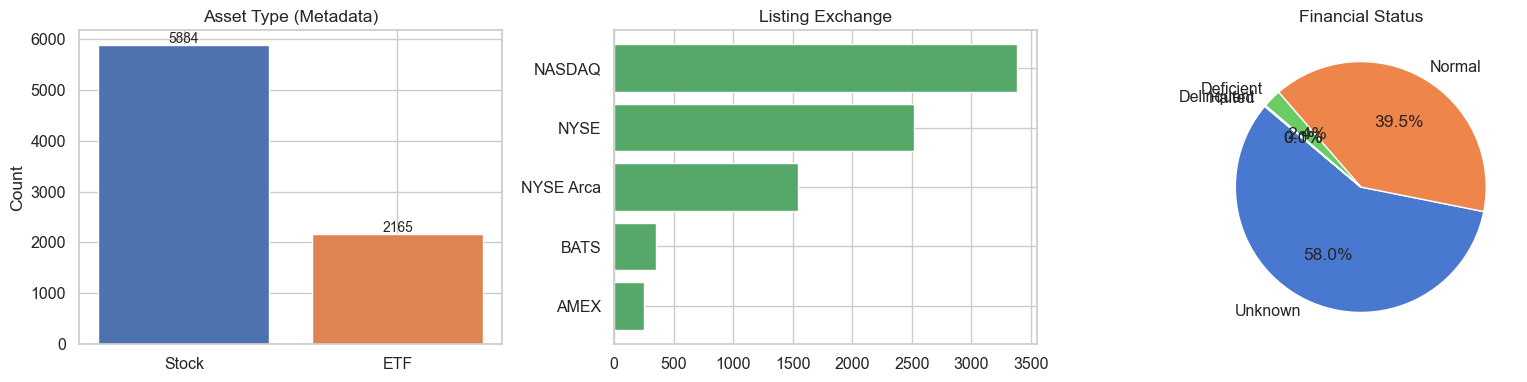

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# ETF vs individual stocks
etf_counts = meta["ETF"].map({"Y": "ETF", "N": "Stock"}).value_counts()
axes[0].bar(etf_counts.index, etf_counts.values, color=["#4C72B0", "#DD8452"])
axes[0].set_title("Asset Type (Metadata)")
axes[0].set_ylabel("Count")
for i, v in enumerate(etf_counts.values):
    axes[0].text(i, v + 50, str(v), ha="center", fontsize=10)

# Listing exchange (N=NYSE, Q=NASDAQ, P=NYSE Arca, A=AMEX, Z=BATS)
exchange_map = {"N": "NYSE", "Q": "NASDAQ", "P": "NYSE Arca", "A": "AMEX", "Z": "BATS"}
exchange_counts = meta["Listing Exchange"].map(exchange_map).value_counts()
axes[1].barh(exchange_counts.index, exchange_counts.values, color="#55A868")
axes[1].set_title("Listing Exchange")
axes[1].invert_yaxis()

# Financial status
status_map = {"N": "Normal", "D": "Deficient", "E": "Delinquent", "H": "Halted", np.nan: "Unknown"}
status_counts = meta["Financial Status"].map(status_map).value_counts()
axes[2].pie(status_counts.values, labels=status_counts.index, autopct="%1.1f%%", startangle=140)
axes[2].set_title("Financial Status")

plt.tight_layout()
plt.show()

In [7]:
# Cross-tab: ETF flag vs exchange
cross = pd.crosstab(
    meta["ETF"].map({"Y": "ETF", "N": "Stock"}),
    meta["Listing Exchange"].map(exchange_map),
    margins=True,
)
print("ETF vs Exchange cross-tabulation:")
display(cross)

ETF vs Exchange cross-tabulation:


Listing Exchange,AMEX,BATS,NASDAQ,NYSE,NYSE Arca,All
ETF,,,,,,
ETF,1,334,395,0,1435,2165
Stock,252,17,2988,2520,107,5884
All,253,351,3383,2520,1542,8049


## 4. File Inventory & Alignment

We verify that metadata symbols align with available CSV files and quantify the on-disk dataset size.

In [8]:
stock_files = {p.stem for p in STOCKS_DIR.glob("*.csv")}
etf_files = {p.stem for p in ETFS_DIR.glob("*.csv")}
meta_symbols = set(meta["Symbol"])

inventory = pd.DataFrame({
    "Category": ["Stock CSV files", "ETF CSV files", "Metadata symbols", "Total CSV files"],
    "Count": [len(stock_files), len(etf_files), len(meta_symbols), len(stock_files) + len(etf_files)],
})
display(inventory)

missing_files = meta_symbols - stock_files - etf_files
orphan_files = (stock_files | etf_files) - meta_symbols
print(f"\nSymbols in metadata without a CSV file: {len(missing_files)}")
if missing_files:
    print(sorted(missing_files))
print(f"CSV files not in metadata: {len(orphan_files)}")
if orphan_files:
    print(sorted(orphan_files))

,Category,Count
0,Stock CSV files,5884
1,ETF CSV files,2165
2,Metadata symbols,8049
3,Total CSV files,8049



Symbols in metadata without a CSV file: 3
['AGM$A', 'CARR.V', 'UTX.V']
CSV files not in metadata: 3
['AGM-A', 'CARR#', 'UTX#']


## 5. Single-Symbol Deep Dive

We start with **Apple (AAPL)** as a representative large-cap stock with long history, then compare a few benchmark symbols.

In [9]:
BENCHMARKS = ["AAPL", "MSFT", "JPM", "XOM", "TSLA"]
benchmark_data = {sym: load_price_data(sym) for sym in BENCHMARKS}

coverage = pd.DataFrame([
    {
        "Symbol": sym,
        "Rows": len(df),
        "Start": df["Date"].min().date(),
        "End": df["Date"].max().date(),
        "Years": round((df["Date"].max() - df["Date"].min()).days / 365.25, 1),
    }
    for sym, df in benchmark_data.items()
])
display(coverage)

,Symbol,Rows,Start,End,Years
0,AAPL,9909,1980-12-12,2020-04-01,39.3
1,MSFT,8584,1986-03-13,2020-04-01,34.1
2,JPM,10098,1980-03-17,2020-04-01,40.0
3,XOM,14663,1962-01-02,2020-04-01,58.2
4,TSLA,2457,2010-06-29,2020-04-01,9.8


In [10]:
aapl = benchmark_data["AAPL"]
print("AAPL — first and last rows:")
display(aapl.head(3))
display(aapl.tail(3))

print("\nDescriptive statistics (AAPL):")
display(aapl.describe().T)

AAPL — first and last rows:


,Date,Open,High,Low,Close,Adj Close,Volume,Symbol
0,1980-12-12,0.513393,0.515625,0.513393,0.513393,0.406782,117258400,AAPL
1,1980-12-15,0.488839,0.488839,0.486607,0.486607,0.385558,43971200,AAPL
2,1980-12-16,0.453125,0.453125,0.450893,0.450893,0.357260,26432000,AAPL


,Date,Open,High,Low,Close,Adj Close,Volume,Symbol
9906,2020-03-30,250.740005,255.520004,249.399994,254.809998,254.809998,41994100,AAPL
9907,2020-03-31,255.600006,262.489990,252.000000,254.289993,254.289993,49250500,AAPL
9908,2020-04-01,246.500000,248.720001,239.130005,240.910004,240.910004,43956200,AAPL



Descriptive statistics (AAPL):


,count,mean,min,25%,50%,75%,max,std
Date,9909,2000-07-30 08:33:08.010899,1980-12-12 00:00:00,1990-10-02 00:00:00,2000-07-21 00:00:00,2010-05-28 00:00:00,2020-04-01 00:00:00,NaN
Open,9909.0,32.606849,0.198661,1.071429,1.729286,35.799999,324.73999,58.415759
High,9909.0,32.936079,0.198661,1.089286,1.758929,36.265713,327.850006,59.001576
Low,9909.0,32.27756,0.196429,1.048571,1.696429,35.328571,323.350006,57.883037
Close,9909.0,32.61803,0.196429,1.071429,1.732143,35.761429,327.200012,58.471899
Adj Close,9909.0,30.57657,0.155638,0.917643,1.466154,31.042374,327.200012,56.746275
Volume,9909.0,85829159.299627,347200.0,33042300.0,57664900.0,106999200.0,1855410200.0,85971948.761355


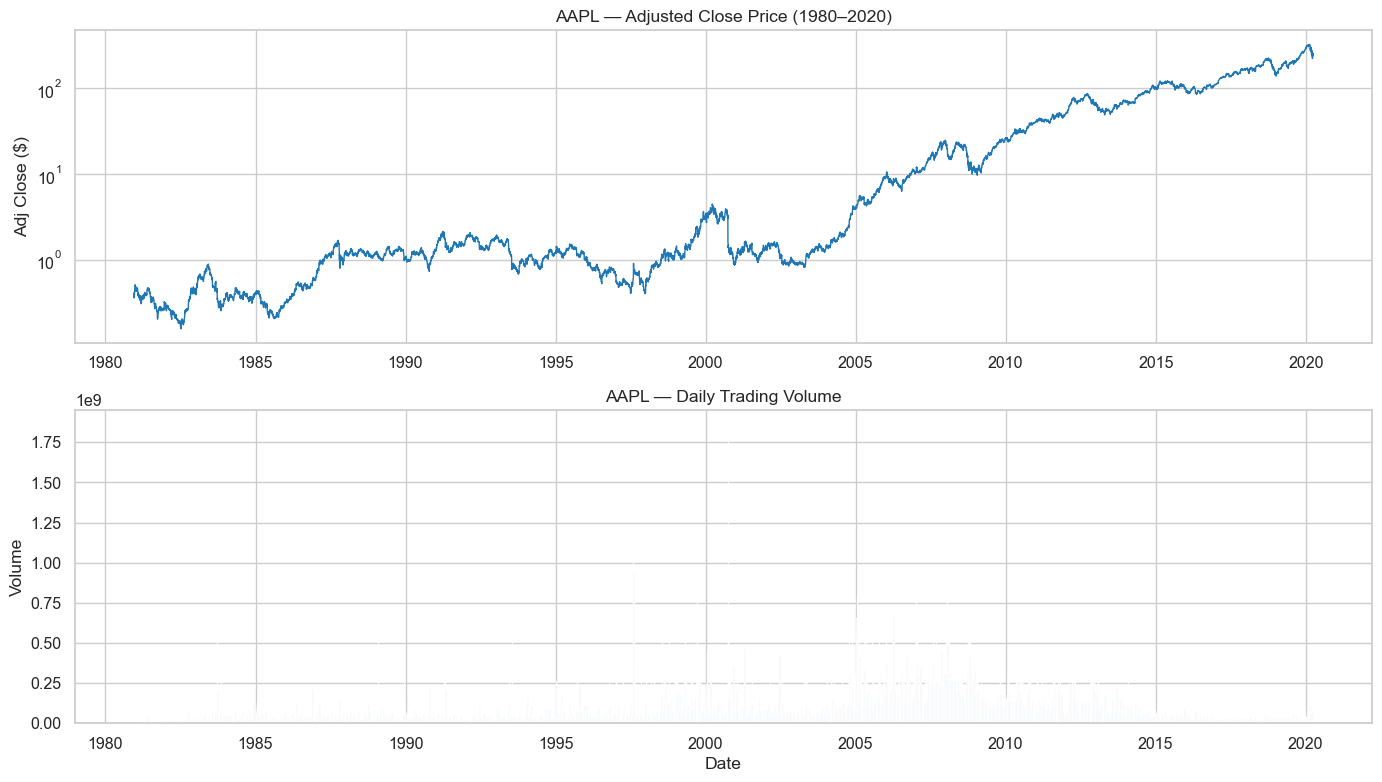

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

# Price history
axes[0].plot(aapl["Date"], aapl["Adj Close"], color="#1f77b4", linewidth=1)
axes[0].set_title("AAPL — Adjusted Close Price (1980–2020)")
axes[0].set_ylabel("Adj Close ($)")
axes[0].set_yscale("log")

# Volume
axes[1].bar(aapl["Date"], aapl["Volume"], width=1, color="#aec7e8", alpha=0.8)
axes[1].set_title("AAPL — Daily Trading Volume")
axes[1].set_ylabel("Volume")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

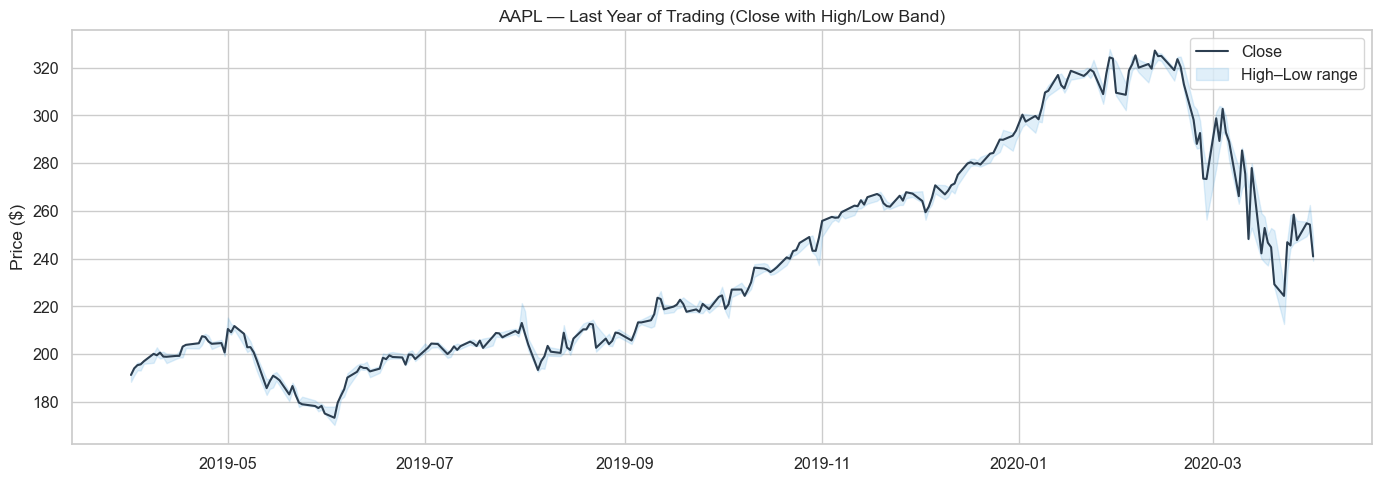

In [12]:
# OHLC candlestick-style view (recent 1 year)
recent = aapl[aapl["Date"] >= "2019-04-01"].copy()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(recent["Date"], recent["Close"], label="Close", color="#2c3e50", linewidth=1.5)
ax.fill_between(recent["Date"], recent["Low"], recent["High"], alpha=0.15, color="#3498db", label="High–Low range")
ax.set_title("AAPL — Last Year of Trading (Close with High/Low Band)")
ax.set_ylabel("Price ($)")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Cross-Sectional Coverage Analysis

Scanning a random sample of stock files reveals how history length, data completeness, and end dates vary across the universe. This is critical for deciding minimum history requirements and train/validation splits.

In [13]:
SAMPLE_SIZE = 500  # increase for more precision; full scan takes several minutes
stock_scan = scan_directory(STOCKS_DIR, sample_size=SAMPLE_SIZE)
etf_scan = scan_directory(ETFS_DIR, sample_size=min(300, len(list(ETFS_DIR.glob("*.csv")))))

stock_scan["asset_type"] = "Stock"
etf_scan["asset_type"] = "ETF"
combined_scan = pd.concat([stock_scan, etf_scan], ignore_index=True)

print(f"Scanned {len(stock_scan)} stocks and {len(etf_scan)} ETFs")
display(combined_scan.describe(include="all").T)

Scanned 500 stocks and 300 ETFs


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
symbol,800,800,BPY,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rows,800.0,NaN,NaN,NaN,3012.9725,3.0,832.75,2020.5,4209.0,14663.0,2832.878546
start_date,800,NaN,NaN,NaN,2008-03-11 22:04:48,1962-01-02 00:00:00,2003-06-15 00:00:00,2012-02-13 00:00:00,2016-12-01 12:00:00,2020-03-25 00:00:00,NaN
end_date,800,NaN,NaN,NaN,2020-04-01 00:03:36,2020-04-01 00:00:00,2020-04-01 00:00:00,2020-04-01 00:00:00,2020-04-01 00:00:00,2020-04-02 00:00:00,NaN
null_count,800.0,NaN,NaN,NaN,0.255,0.0,0.0,0.0,0.0,54.0,2.311201
zero_volume_days,800.0,NaN,NaN,NaN,161.2175,0.0,0.0,6.0,84.25,3484.0,426.473413
duplicate_dates,800.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0
asset_type,800,2,Stock,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN


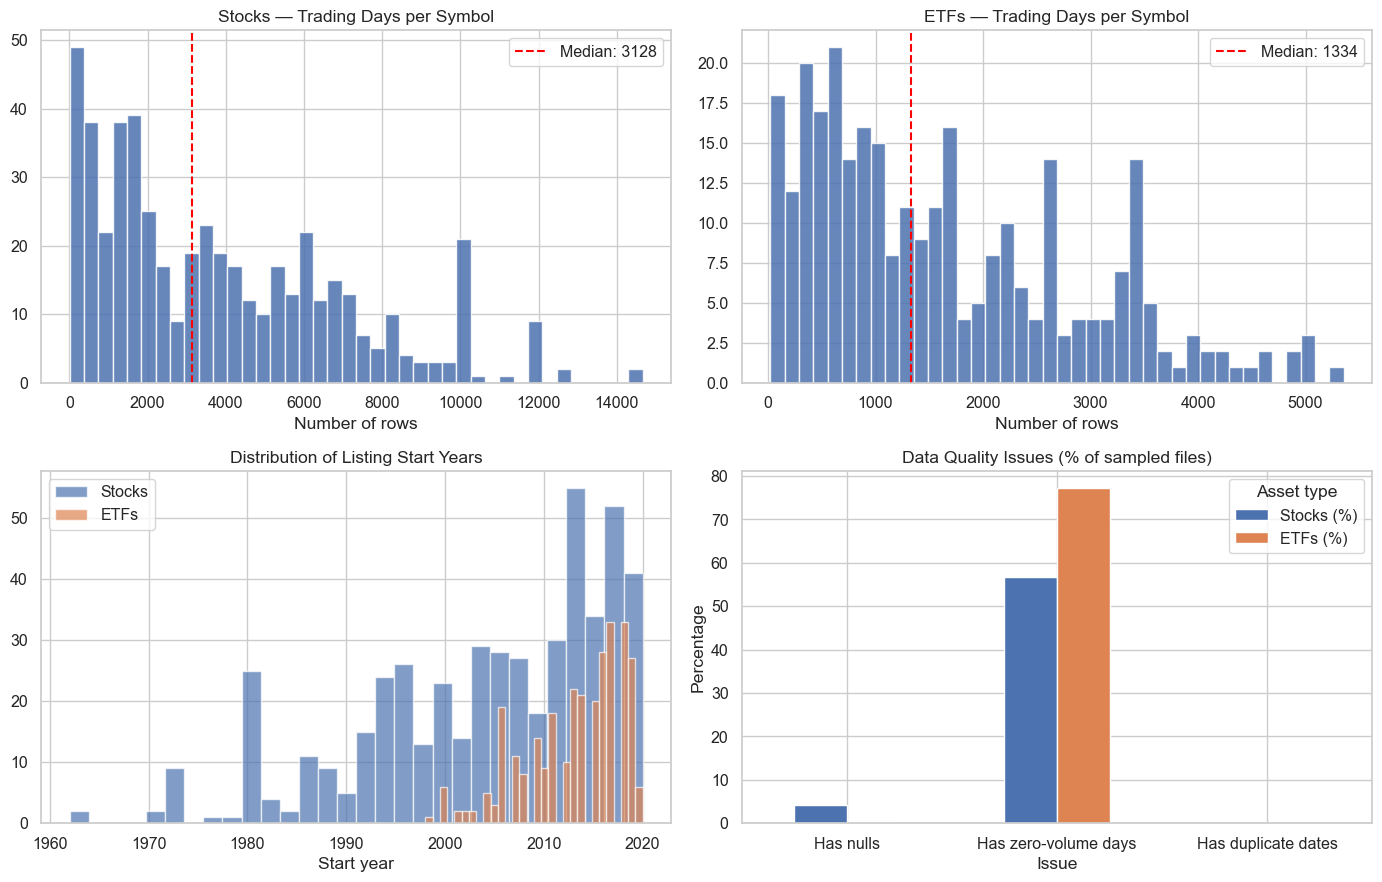

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# History length distribution
for ax, subset, label in zip(
    [axes[0, 0], axes[0, 1]],
    [stock_scan, etf_scan],
    ["Stocks", "ETFs"],
):
    ax.hist(subset["rows"], bins=40, color="#4C72B0", edgecolor="white", alpha=0.85)
    ax.axvline(subset["rows"].median(), color="red", linestyle="--", label=f"Median: {subset['rows'].median():.0f}")
    ax.set_title(f"{label} — Trading Days per Symbol")
    ax.set_xlabel("Number of rows")
    ax.legend()

# Start year distribution
stock_scan["start_year"] = pd.to_datetime(stock_scan["start_date"]).dt.year
etf_scan["start_year"] = pd.to_datetime(etf_scan["start_date"]).dt.year
axes[1, 0].hist(stock_scan["start_year"], bins=30, alpha=0.7, label="Stocks", color="#4C72B0")
axes[1, 0].hist(etf_scan["start_year"], bins=30, alpha=0.7, label="ETFs", color="#DD8452")
axes[1, 0].set_title("Distribution of Listing Start Years")
axes[1, 0].set_xlabel("Start year")
axes[1, 0].legend()

# Data quality flags
quality_flags = pd.DataFrame({
    "Issue": ["Has nulls", "Has zero-volume days", "Has duplicate dates"],
    "Stocks (%)": [
        100 * (stock_scan["null_count"] > 0).mean(),
        100 * (stock_scan["zero_volume_days"] > 0).mean(),
        100 * (stock_scan["duplicate_dates"] > 0).mean(),
    ],
    "ETFs (%)": [
        100 * (etf_scan["null_count"] > 0).mean(),
        100 * (etf_scan["zero_volume_days"] > 0).mean(),
        100 * (etf_scan["duplicate_dates"] > 0).mean(),
    ],
})
quality_flags.plot(x="Issue", kind="bar", ax=axes[1, 1], rot=0, color=["#4C72B0", "#DD8452"])
axes[1, 1].set_title("Data Quality Issues (% of sampled files)")
axes[1, 1].set_ylabel("Percentage")
axes[1, 1].legend(title="Asset type")

plt.tight_layout()
plt.show()

In [15]:
# Symbols with very short history — problematic for sequence models
MIN_DAYS = 252 * 2  # ~2 years of trading days
short_history = stock_scan[stock_scan["rows"] < MIN_DAYS].sort_values("rows")
print(f"Stocks with < {MIN_DAYS} trading days (in sample): {len(short_history)} / {len(stock_scan)} "
      f"({100 * len(short_history) / len(stock_scan):.1f}%)")
display(short_history.head(10))

Stocks with < 504 trading days (in sample): 64 / 500 (12.8%)


,symbol,rows,start_date,end_date,null_count,zero_volume_days,duplicate_dates,asset_type,start_year
245,METX,3,2019-10-02,2020-04-01,0,1,0,Stock,2019
225,DFNS,6,2020-03-25,2020-04-01,0,5,0,Stock,2020
34,ESSC,9,2020-03-20,2020-04-01,0,2,0,Stock,2020
64,PASG,24,2020-02-28,2020-04-01,0,0,0,Stock,2020
347,OBLG,34,2019-09-11,2020-04-01,0,0,0,Stock,2019
430,PPD,39,2020-02-06,2020-04-01,0,0,0,Stock,2020
280,BEAM,39,2020-02-06,2020-04-01,0,0,0,Stock,2020
435,BPYU,44,2019-09-04,2020-04-01,0,0,0,Stock,2019
394,HCCO,46,2020-01-28,2020-04-01,0,21,0,Stock,2020
357,BSBK,53,2020-01-16,2020-04-01,0,0,0,Stock,2020


## 7. Returns & Volatility Analysis

For RNN modeling, **returns** (not raw prices) are typically used as inputs/targets because prices are non-stationary. We examine return distributions, volatility clustering, and autocorrelation — all key considerations for sequence models.

In [16]:
aapl_ret = add_returns(aapl)
aapl_ret = aapl_ret.dropna(subset=["log_return"])

print("Return statistics (AAPL, daily log returns):")
display(aapl_ret[["log_return", "simple_return", "intraday_range", "overnight_gap"]].describe().T)

Return statistics (AAPL, daily log returns):


,count,mean,std,min,25%,50%,75%,max
log_return,9908.0,0.000644,0.029188,-0.731247,-0.013365,0.000000,0.014637,0.286891
simple_return,9908.0,0.001065,0.028735,-0.518692,-0.013276,0.000000,0.014745,0.332278
intraday_range,9908.0,0.031901,0.021867,0.000000,0.017124,0.027174,0.040805,0.349315
overnight_gap,9908.0,0.001173,0.016855,-0.473131,-0.003731,0.000000,0.006031,0.278481


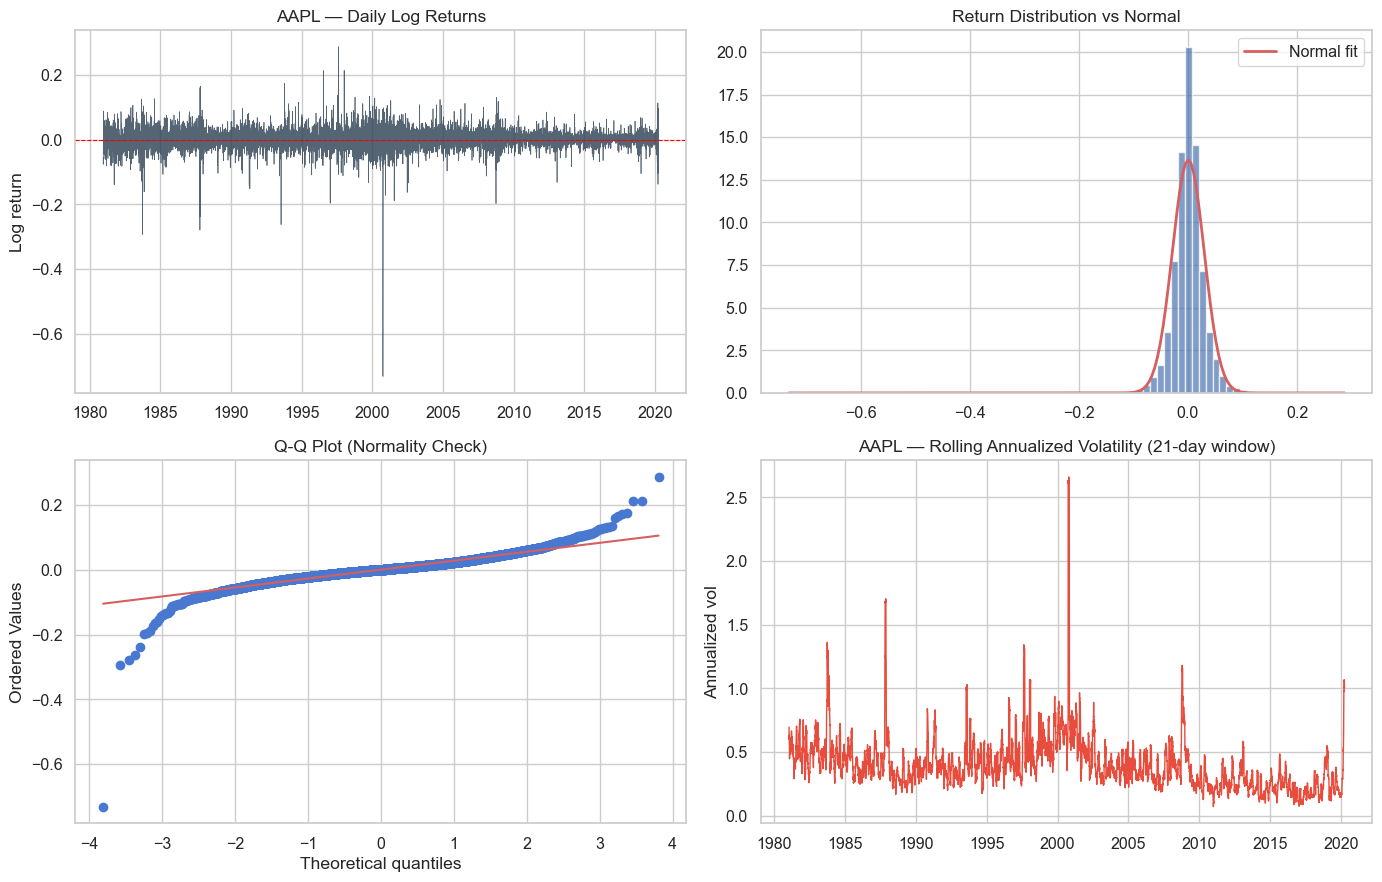

Excess kurtosis: 46.72 (normal = 0)
Skewness: -1.767


In [17]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Return time series
axes[0, 0].plot(aapl_ret["Date"], aapl_ret["log_return"], linewidth=0.5, color="#2c3e50", alpha=0.8)
axes[0, 0].set_title("AAPL — Daily Log Returns")
axes[0, 0].set_ylabel("Log return")
axes[0, 0].axhline(0, color="red", linewidth=0.8, linestyle="--")

# Return distribution
axes[0, 1].hist(aapl_ret["log_return"], bins=80, density=True, alpha=0.7, color="#4C72B0", edgecolor="white")
x = np.linspace(aapl_ret["log_return"].min(), aapl_ret["log_return"].max(), 200)
axes[0, 1].plot(x, stats.norm.pdf(x, aapl_ret["log_return"].mean(), aapl_ret["log_return"].std()),
                "r-", linewidth=2, label="Normal fit")
axes[0, 1].set_title("Return Distribution vs Normal")
axes[0, 1].legend()

# Q-Q plot
stats.probplot(aapl_ret["log_return"], dist="norm", plot=axes[1, 0])
axes[1, 0].set_title("Q-Q Plot (Normality Check)")

# Rolling volatility (21-day ≈ 1 month)
rolling_vol = aapl_ret["log_return"].rolling(21).std() * np.sqrt(252)
axes[1, 1].plot(aapl_ret["Date"], rolling_vol, color="#e74c3c", linewidth=1)
axes[1, 1].set_title("AAPL — Rolling Annualized Volatility (21-day window)")
axes[1, 1].set_ylabel("Annualized vol")

plt.tight_layout()
plt.show()

# Fat tails
print(f"Excess kurtosis: {aapl_ret['log_return'].kurtosis():.2f} (normal = 0)")
print(f"Skewness: {aapl_ret['log_return'].skew():.3f}")

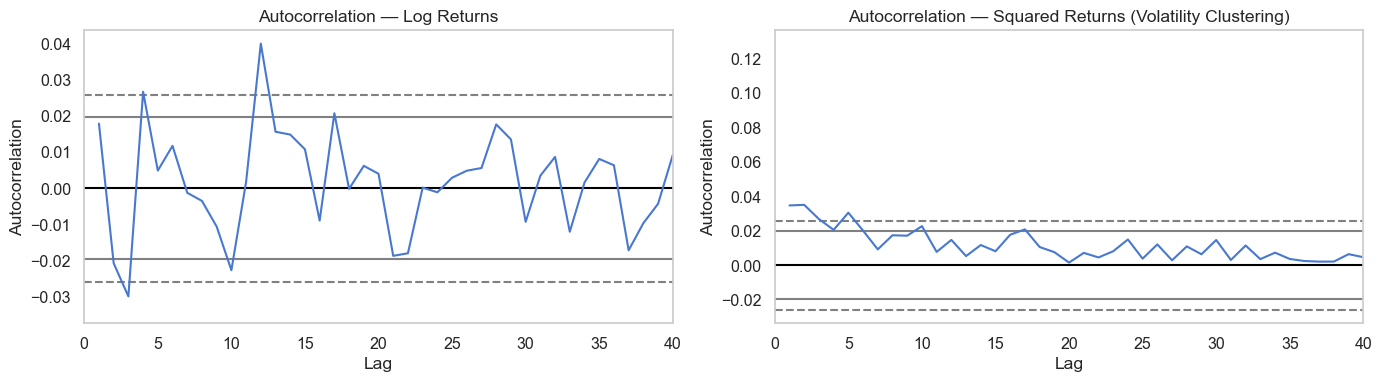

In [18]:
# Autocorrelation of returns and squared returns (volatility clustering)
from pandas.plotting import autocorrelation_plot

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

pd.plotting.autocorrelation_plot(aapl_ret["log_return"].dropna(), ax=axes[0])
axes[0].set_title("Autocorrelation — Log Returns")
axes[0].set_xlim(0, 40)

pd.plotting.autocorrelation_plot(aapl_ret["log_return"].dropna() ** 2, ax=axes[1])
axes[1].set_title("Autocorrelation — Squared Returns (Volatility Clustering)")
axes[1].set_xlim(0, 40)

plt.tight_layout()
plt.show()

Comparing last 2,456 trading days per symbol


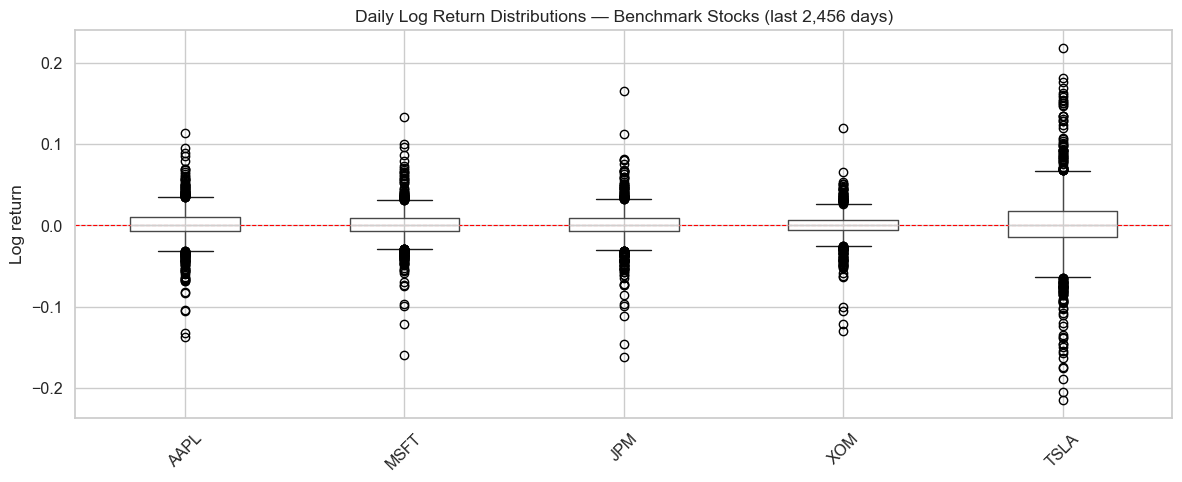

In [19]:
# Compare return distributions across benchmark stocks
# Symbols have different history lengths — use the last N trading days,
# where N is the shortest non-null return series among benchmarks.
return_series = {
    sym: add_returns(df)["log_return"].dropna()
    for sym, df in benchmark_data.items()
}
min_len = min(len(s) for s in return_series.values())
returns_aligned = pd.DataFrame({
    sym: s.tail(min_len).values
    for sym, s in return_series.items()
})

print(f"Comparing last {min_len:,} trading days per symbol")

fig, ax = plt.subplots(figsize=(12, 5))
returns_aligned.boxplot(ax=ax, rot=45)
ax.set_title(f"Daily Log Return Distributions — Benchmark Stocks (last {min_len:,} days)")
ax.set_ylabel("Log return")
ax.axhline(0, color="red", linestyle="--", linewidth=0.8)
plt.tight_layout()
plt.show()

## 8. Volume & Liquidity Patterns

Volume is a useful auxiliary feature for RNNs. We examine its distribution, relationship with absolute returns, and long-term trends.

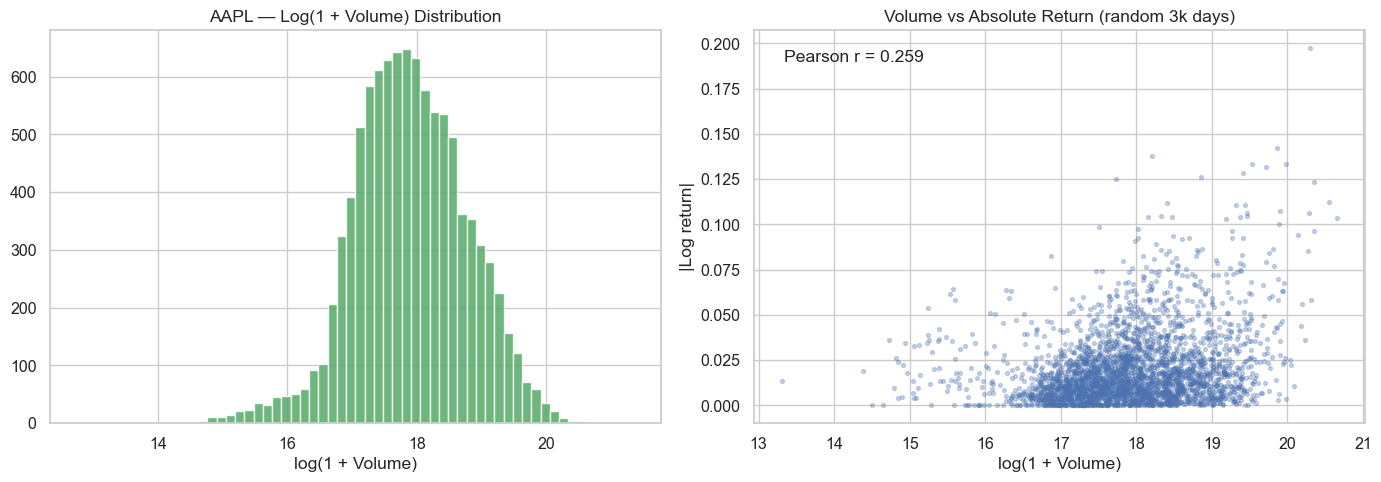

In [20]:
aapl_vol = aapl.copy()
aapl_vol["log_volume"] = np.log1p(aapl_vol["Volume"])
aapl_vol["abs_return"] = add_returns(aapl_vol)["log_return"].abs()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(aapl_vol["log_volume"], bins=60, color="#55A868", edgecolor="white", alpha=0.85)
axes[0].set_title("AAPL — Log(1 + Volume) Distribution")
axes[0].set_xlabel("log(1 + Volume)")

sample_idx = np.random.default_rng(42).choice(len(aapl_vol.dropna()), size=3000, replace=False)
scatter_df = aapl_vol.dropna().iloc[sample_idx]
axes[1].scatter(scatter_df["log_volume"], scatter_df["abs_return"], alpha=0.3, s=8, color="#4C72B0")
axes[1].set_title("Volume vs Absolute Return (random 3k days)")
axes[1].set_xlabel("log(1 + Volume)")
axes[1].set_ylabel("|Log return|")

corr = aapl_vol[["log_volume", "abs_return"]].corr().iloc[0, 1]
axes[1].text(0.05, 0.95, f"Pearson r = {corr:.3f}", transform=axes[1].transAxes, va="top")

plt.tight_layout()
plt.show()

## 9. Market-Wide Correlation Structure

Understanding how stocks move together informs whether we model symbols independently or incorporate market/sector factors. We use SPY (S&P 500 ETF) as a market benchmark.

Aligned return matrix: 1321 days × 6 symbols


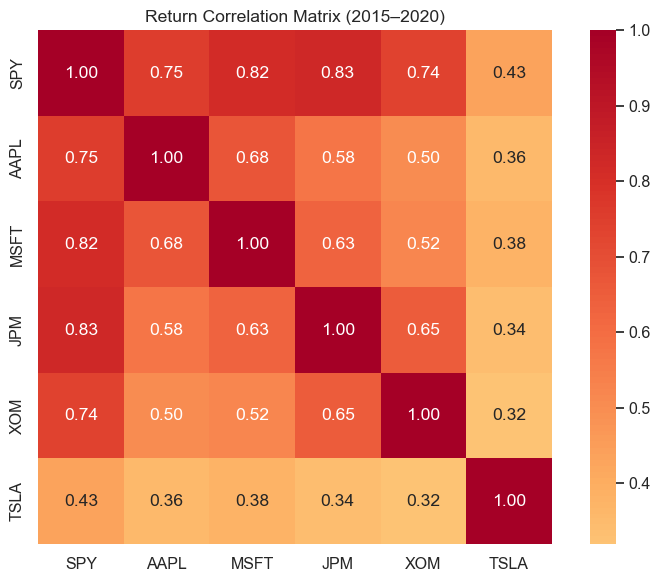

In [21]:
spy = load_price_data("SPY", asset_type="etf")

# Align benchmark returns on a shared calendar (merge on Date, not row position)
start = pd.Timestamp("2015-01-01")
aligned_returns = (
    add_returns(spy)
    .set_index("Date")[["log_return"]]
    .rename(columns={"log_return": "SPY"})
)
for sym, df in benchmark_data.items():
    r = (
        add_returns(df)
        .set_index("Date")[["log_return"]]
        .rename(columns={"log_return": sym})
    )
    aligned_returns = aligned_returns.join(r, how="outer")

aligned_returns = aligned_returns.loc[start:].dropna()
print(f"Aligned return matrix: {aligned_returns.shape[0]} days × {aligned_returns.shape[1]} symbols")

corr_matrix = aligned_returns.corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdYlBu_r", center=0, ax=ax, square=True)
ax.set_title("Return Correlation Matrix (2015–2020)")
plt.tight_layout()
plt.show()

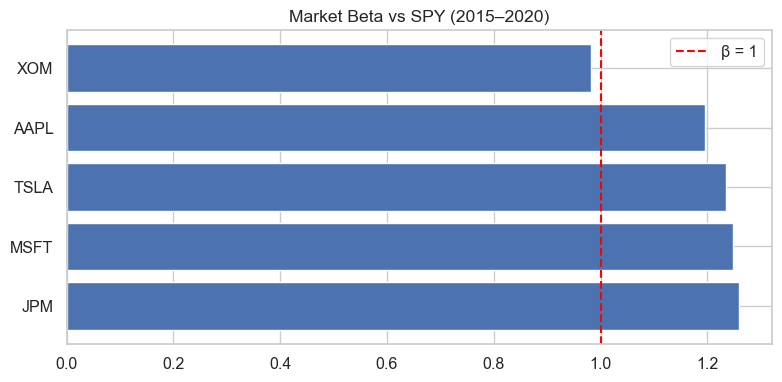

In [22]:
# Beta vs market (SPY) for benchmark stocks
betas = {}
for sym in BENCHMARKS:
    if sym in aligned_returns.columns:
        cov = aligned_returns[["SPY", sym]].cov().iloc[0, 1]
        var = aligned_returns["SPY"].var()
        betas[sym] = cov / var

beta_df = pd.DataFrame({"Symbol": list(betas.keys()), "Beta vs SPY": list(betas.values())})
beta_df = beta_df.sort_values("Beta vs SPY", ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(beta_df["Symbol"], beta_df["Beta vs SPY"], color="#4C72B0")
ax.axvline(1.0, color="red", linestyle="--", label="β = 1")
ax.set_title("Market Beta vs SPY (2015–2020)")
ax.legend()
plt.tight_layout()
plt.show()

## 10. Missing Trading Days & Calendar Effects

Gaps in trading calendars and day-of-week effects can influence how we construct RNN sequence windows.

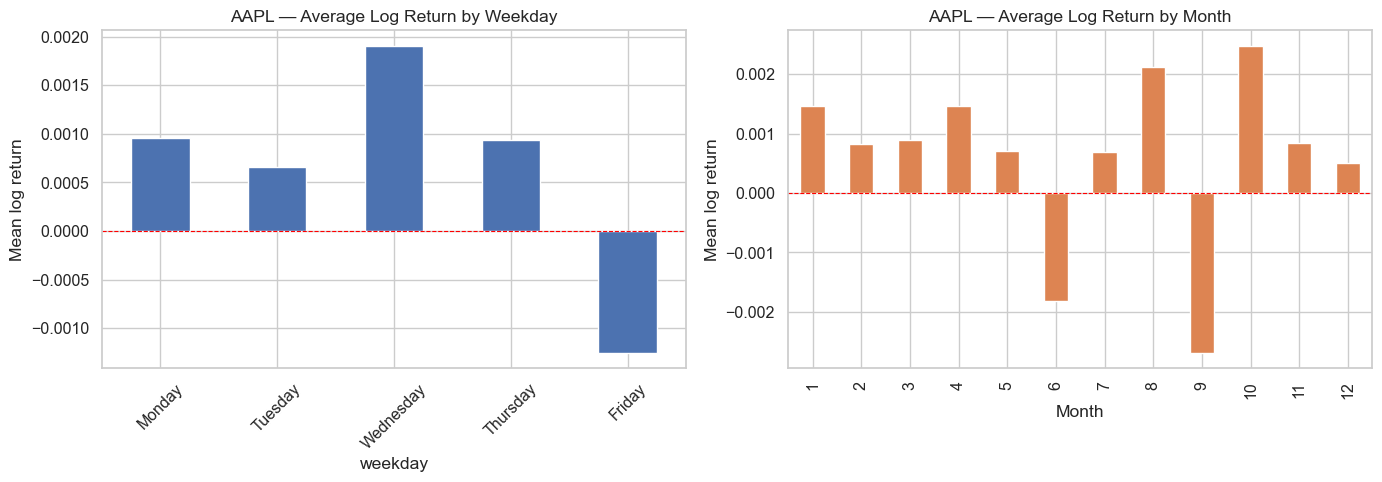

In [23]:
aapl_cal = aapl.copy()
aapl_cal["weekday"] = aapl_cal["Date"].dt.day_name()
aapl_cal["month"] = aapl_cal["Date"].dt.month
aapl_cal = add_returns(aapl_cal)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Day-of-week average return
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
dow_returns = aapl_cal.groupby("weekday")["log_return"].mean().reindex(dow_order)
dow_returns.plot(kind="bar", ax=axes[0], color="#4C72B0", edgecolor="white")
axes[0].set_title("AAPL — Average Log Return by Weekday")
axes[0].set_ylabel("Mean log return")
axes[0].axhline(0, color="red", linestyle="--", linewidth=0.8)
axes[0].tick_params(axis="x", rotation=45)

# Monthly seasonality
month_returns = aapl_cal.groupby("month")["log_return"].mean()
month_returns.plot(kind="bar", ax=axes[1], color="#DD8452", edgecolor="white")
axes[1].set_title("AAPL — Average Log Return by Month")
axes[1].set_ylabel("Mean log return")
axes[1].set_xlabel("Month")
axes[1].axhline(0, color="red", linestyle="--", linewidth=0.8)

plt.tight_layout()
plt.show()

In [24]:
# Gap analysis: days between consecutive observations
aapl_gaps = aapl.copy()
aapl_gaps["gap_days"] = aapl_gaps["Date"].diff().dt.days

print("Gap between trading days (should be 1 for weekdays, 3 for Mon after Fri, etc.):")
display(aapl_gaps["gap_days"].value_counts().head(10))

long_gaps = aapl_gaps[aapl_gaps["gap_days"] > 5]
print(f"\nGaps > 5 calendar days: {len(long_gaps)} (holidays, halts, data issues)")
if len(long_gaps) > 0:
    display(long_gaps[["Date", "gap_days"]].head(10))

Gap between trading days (should be 1 for weekdays, 3 for Mon after Fri, etc.):


gap_days
1.0    7763
3.0    1805
4.0     243
2.0      94
5.0       2
7.0       1
Name: count, dtype: int64


Gaps > 5 calendar days: 1 (holidays, halts, data issues)


,Date,gap_days
5241,2001-09-17,7.0


## 11. Stationarity & Target Variable Considerations

RNNs benefit from stationary inputs. We compare stationarity of price levels vs returns using a rolling mean/std visual check and discuss implications for the modeling target.

**Minimum:** Run Sections 1–2 first (imports + helper functions). `aapl` / `aapl_ret` load automatically if missing.

In [4]:
import matplotlib.pyplot as plt

if "ensure_aapl_returns" not in globals():
    raise RuntimeError("Run Section 1 (imports) and Section 2 (helper functions) first.")

aapl, aapl_ret = ensure_aapl_returns()

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

plot_specs = [
    (aapl["Date"], aapl["Adj Close"], "Adj Close (non-stationary)"),
    (aapl_ret["Date"], aapl_ret["log_return"], "Log Returns (more stationary)"),
]

for ax, (dates, series, title) in zip(axes.flat, plot_specs):
    rolling_mean = series.rolling(252).mean()
    rolling_std = series.rolling(252).std()
    ax.plot(dates, rolling_mean, label="252-day rolling mean", linewidth=1)
    ax.plot(dates, rolling_std, label="252-day rolling std", linewidth=1, alpha=0.8)
    ax.set_title(title)
    ax.legend(fontsize=8)

plt.suptitle("Rolling Statistics — Stationarity Visual Check (AAPL)", y=1.02)
plt.tight_layout()
plt.show()

RuntimeError: Missing variables: ['plt', 'aapl', 'aapl_ret']. After a kernel restart, run the notebook from the top (Setup → Helpers → AAPL load → Returns analysis) before this cell.

In [ ]:
# Potential target definitions for the RNN (preview)
if "ensure_aapl_returns" not in globals():
    raise RuntimeError("Run Section 1 (imports) and Section 2 (helper functions) first.")

aapl, aapl_ret = ensure_aapl_returns()

preview = aapl_ret[["Date", "Adj Close", "log_return"]].copy()
preview["next_day_return"] = preview["log_return"].shift(-1)
preview["next_5d_return"] = preview["log_return"].shift(-1).rolling(5).sum().shift(-4)
preview["direction_next_day"] = (preview["next_day_return"] > 0).astype(int)

print("Target variable preview (classification vs regression):")
display(preview.dropna().tail(5))

print(f"\nNext-day direction balance (1=up): {preview['direction_next_day'].mean():.3f}")
print("(Close to 0.5 suggests relatively balanced classes for direction prediction)")

## 12. Feature Engineering Preview

A preview of features commonly fed into RNN/LSTM models for stock prediction. Full implementation will be in the modeling notebook.

In [ ]:
def engineer_features(df: pd.DataFrame, price_col: str = "Adj Close") -> pd.DataFrame:
    """Create a feature matrix suitable for sequence modeling."""
    out = df.copy()
    out["log_return"] = np.log(out[price_col] / out[price_col].shift(1))
    out["log_volume"] = np.log1p(out["Volume"])
    out["intraday_range"] = (out["High"] - out["Low"]) / out["Close"]

    for window in [5, 10, 21]:
        out[f"return_ma_{window}"] = out["log_return"].rolling(window).mean()
        out[f"volatility_{window}"] = out["log_return"].rolling(window).std()
        out[f"volume_ma_{window}"] = out["log_volume"].rolling(window).mean()

    out["rsi_14"] = _compute_rsi(out[price_col], 14)
    return out


def _compute_rsi(series: pd.Series, period: int = 14) -> pd.Series:
    delta = series.diff()
    gain = delta.clip(lower=0).rolling(period).mean()
    loss = (-delta.clip(upper=0)).rolling(period).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))


features = engineer_features(aapl)
feature_cols = [c for c in features.columns if c not in ["Date", "Symbol", "Open", "High", "Low", "Close", "Adj Close", "Volume"]]
print(f"Engineered {len(feature_cols)} features:")
print(feature_cols)

display(features[feature_cols].dropna().describe().T)

In [ ]:
# Feature correlation heatmap (recent period)
feat_recent = features[feature_cols].dropna().tail(500)
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(feat_recent.corr(), cmap="coolwarm", center=0, ax=ax, square=True)
ax.set_title("Feature Correlation Matrix (last 500 trading days, AAPL)")
plt.tight_layout()
plt.show()

## 13. COVID-19 Period Stress Test

The dataset ends in early April 2020, capturing the initial COVID-19 market crash. This regime is important for understanding extreme volatility and for designing robust validation splits.

In [ ]:
crash_period = aapl_ret[(aapl_ret["Date"] >= "2020-02-01") & (aapl_ret["Date"] <= "2020-04-01")]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(crash_period["Date"], crash_period["Adj Close"], color="#c0392b", linewidth=2)
axes[0].set_title("AAPL — COVID Crash Period (Feb–Apr 2020)")
axes[0].set_ylabel("Adj Close ($)")

axes[1].bar(crash_period["Date"], crash_period["log_return"],
            color=np.where(crash_period["log_return"] >= 0, "#27ae60", "#c0392b"), width=0.8)
axes[1].set_title("Daily Log Returns During COVID Crash")
axes[1].axhline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

print(f"Max daily drop: {crash_period['log_return'].min():.4f} ({np.exp(crash_period['log_return'].min()) - 1:.2%})")
print(f"Max daily gain: {crash_period['log_return'].max():.4f} ({np.exp(crash_period['log_return'].max()) - 1:.2%})")
print(f"Period cumulative return: {crash_period['log_return'].sum():.4f} ({np.exp(crash_period['log_return'].sum()) - 1:.2%})")

---

## 14. Key Findings & Implications for RNN Modeling

### Data Structure
- **~8,049 symbols** in metadata; **~5,884 stocks** and **~2,165 ETFs** with daily OHLCV data.
- Each file contains standard columns: `Date`, `Open`, `High`, `Low`, `Close`, `Adj Close`, `Volume`.
- Data is **per-symbol, per-file** — ideal for single-series RNNs or panel models with symbol embeddings.

### Coverage & Quality
- History length varies widely (median ~3,200 trading days for stocks; some symbols have < 1 year).
- Most files end on **2020-04-01**; a few end on 2020-04-02.
- Minor quality issues: ~6% of sampled files have nulls; ~60% have zero-volume days; duplicate dates are rare.
- **Recommendation:** Filter symbols with minimum history (e.g., ≥ 2–3 years) and handle zero-volume days.

### Statistical Properties
- **Returns are fat-tailed** (excess kurtosis >> 0) and slightly negatively skewed — not normally distributed.
- **Volatility clusters** (significant autocorrelation in squared returns) — RNNs/LSTMs can potentially capture this.
- Raw prices are **non-stationary**; log returns are more suitable as model inputs/targets.
- Next-day direction is roughly **balanced** (~50/50 up/down), useful for classification tasks.

### Feature Candidates for RNN Input
| Feature | Rationale |
|---------|-----------|
| Log returns | Stationary, scale-comparable across symbols |
| Log volume | Liquidity signal; stabilizes heavy-tailed volume |
| Rolling volatility (5/10/21-day) | Captures regime changes |
| Rolling return MA | Momentum / trend signal |
| Intraday range (High–Low)/Close | Daily volatility proxy |
| RSI(14) | Overbought/oversold indicator |
| Market return (SPY) | Systematic risk factor |

### Modeling Decisions to Make Next
1. **Target variable:** Next-day return (regression) vs direction (classification) vs multi-day horizon?
2. **Universe:** Single stock (e.g., AAPL) vs portfolio of liquid stocks vs ETFs only?
3. **Sequence length:** How many past days should the RNN look back (e.g., 30, 60, 120)?
4. **Train/val/test split:** Time-based split essential; consider holding out COVID period (2020 Q1) as stress test.
5. **Normalization:** Per-symbol z-score or min-max on features within rolling windows?
6. **Architecture:** Vanilla RNN vs LSTM vs GRU; univariate vs multivariate sequences.
7. **Baseline:** Compare RNN against naive (last return, moving average) and linear models.

---

*Next step: `02_modeling_strategy.ipynb` — define the RNN approach based on these findings.*